# Data Source B: Medi-Cal Eligibility Demographics

This notebook analyzes DHCS Medi-Cal certified-eligible counts for Riverside and San Bernardino counties (the Inland Empire), using the demographic tables in Data Source B. It examines enrollment scale and trends, age, primary language, race/ethnicity, Medicare dual status, and delivery system/plan composition. Because these are county-level aggregates, they are **not** IEHP-specific member counts and do not identify immigration status or UIS members.

Counts are certified eligibles, exclude beneficiaries who have not met a monthly share-of-cost obligation, and can be suppressed. Recent months are preliminary and subject to revision. Interpret subgroup percentages as shares of reported counts; suppressed values are not zero.

## 1. Set Up Python Environment and Imports

Install dependencies in the notebook's selected environment if any import below is unavailable. The code searches upward from the notebook working directory for the competition data folder, so it works from the repository root or a nested folder.

In [13]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

COUNTIES = ["Riverside", "San Bernardino"]
COUNTY_LABELS = {county: county for county in COUNTIES}
SOURCE_B_DIR = Path("data/demand-side/B-medical-eligibles-by-demographics")
TABLE_FILES = {
    "age_sex": "by-age-group-and-sex-certified-eligibles.csv",
    "primary_language": "by-primary-language-certified-eligibles.csv",
    "race_age": "by-race-ethnicity-and-age-group-certified-eligibles.csv",
    "dual_age": "by-medicare-dual-status-and-age-group-certified-eligibles.csv",
    "dual_status": "by-medicare-dual-status-certified-eligibles.csv",
    "delivery_plan": "by-delivery-system-and-plan-certified-eligibles.csv",
}

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / SOURCE_B_DIR).is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError(f"Could not find {SOURCE_B_DIR} from {Path.cwd()}")
source_b_dir = repo_root / SOURCE_B_DIR
output_dir = repo_root / "analysis_outputs" / "source_b"
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Repository root: {repo_root}")
print(f"Source B folder: {source_b_dir}")
print(f"Output folder: {output_dir}")

Repository root: /Users/Jonny/ceo-challenge/IEHP-CEO-Competition
Source B folder: /Users/Jonny/ceo-challenge/IEHP-CEO-Competition/data/demand-side/B-medical-eligibles-by-demographics
Output folder: /Users/Jonny/ceo-challenge/IEHP-CEO-Competition/analysis_outputs/source_b


## 2. Load Data Source B

Load the six relevant Source B tables as text first, preserving categorical labels and suppressions. The aid-category tables are intentionally excluded: the competition guide warns against using them to infer immigration status.

In [14]:
tables_raw = {}
for table_name, filename in TABLE_FILES.items():
    path = source_b_dir / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    tables_raw[table_name] = pd.read_csv(
        path,
        dtype="string",
        encoding="utf-8-sig",
        keep_default_na=False,
    )

load_check = pd.DataFrame(
    {name: {"rows": len(frame), "columns": len(frame.columns), "first_month": frame["Month of Eligibility"].min(), "last_month": frame["Month of Eligibility"].max()}
     for name, frame in tables_raw.items()}
).T
print("Loaded Source B tables:")
display(load_check)
print("\nAge/sex preview:")
display(tables_raw["age_sex"].head())

month_sets = [set(frame["Month of Eligibility"].dropna()) for frame in tables_raw.values()]
common_months = sorted(set.intersection(*month_sets))
if not common_months:
    raise ValueError("The Source B tables do not share a reporting month.")
selected_month = common_months[-1]
selected_month_dt = pd.Period(selected_month, freq="M")
print(f"Latest month common to all six tables: {selected_month}")

Loaded Source B tables:


,rows,columns,first_month,last_month
age_sex,93469,9,2010-01,2026-10
primary_language,252912,9,2010-01,2026-10
race_age,277204,9,2010-01,2026-10
dual_age,85727,9,2010-01,2026-10
dual_status,23520,8,2010-01,2026-10
delivery_plan,49920,9,2010-01,2026-10



Age/sex preview:


,Month of Eligibility,County,Age Group,Gender,Total Eligibles,Annotation Code,Annotation Description,Status,Date of Data
0,2026-10,Alameda,Age 00-18,Female,"62,268",,,P,07OCT2026
1,2026-10,Alameda,Age 00-18,Male,"65,509",,,P,07OCT2026
2,2026-10,Alameda,Age 19-44,Female,"86,375",,,P,07OCT2026
3,2026-10,Alameda,Age 19-44,Male,"72,664",,,P,07OCT2026
4,2026-10,Alameda,Age 45-64,Female,"47,392",,,P,07OCT2026


Latest month common to all six tables: 2026-10


## 3. Profile Schema and Data Quality

Profile each source table before transforming it. Nulls include blank source fields; count columns are text in the source and may contain annotations instead of numeric values. Tukey flags are screening signals only, not errors.

In [15]:
def to_numeric_count(values: pd.Series) -> pd.Series:
    """Parse displayed integer counts; nonnumeric/suppressed cells remain missing."""
    return pd.to_numeric(
        values.astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

profile_rows = []
for table_name, frame in tables_raw.items():
    duplicates = int(frame.duplicated().sum())
    for column in frame.columns:
        raw = frame[column].astype("string")
        trimmed = raw.str.strip()
        numeric = to_numeric_count(raw) if column == "Total Eligibles" else pd.Series(dtype="float64")
        positive_numeric = numeric.dropna()
        if len(positive_numeric) >= 4:
            q1, q3 = positive_numeric.quantile([0.25, 0.75])
            iqr = q3 - q1
            outlier_count = int(((positive_numeric < q1 - 1.5 * iqr) | (positive_numeric > q3 + 1.5 * iqr)).sum())
        else:
            outlier_count = 0
        profile_rows.append({
            "table": table_name,
            "column": column,
            "dtype": str(frame[column].dtype),
            "missing_n": int(raw.isna().sum() + raw.eq("").sum()),
            "missing_pct": float(raw.isna().sum() + raw.eq("").sum()) / max(len(frame), 1),
            "unique_n": int(trimmed.replace("", pd.NA).nunique(dropna=True)),
            "whitespace_values_n": int((raw.notna() & raw.ne(trimmed)).sum()),
            "tukey_count_outliers_n": outlier_count,
            "table_duplicate_rows_n": duplicates,
        })

profile_df = pd.DataFrame(profile_rows)
display(profile_df.sort_values(["table", "column"]).reset_index(drop=True))

for table_name in ["age_sex", "primary_language", "race_age", "dual_age", "delivery_plan"]:
    frame = tables_raw[table_name]
    dimensions = [column for column in frame.columns if column not in {
        "Month of Eligibility", "County", "Total Eligibles", "Annotation Code",
        "Annotation Description", "Status", "Date of Data", "Difference"
    }]
    print(f"\n{table_name} category values:")
    for column in dimensions:
        print(f"  {column}: {sorted(frame[column].dropna().astype(str).str.strip().unique().tolist())[:30]}")

,table,column,dtype,missing_n,missing_pct,unique_n,whitespace_values_n,tukey_count_outliers_n,table_duplicate_rows_n
0,age_sex,Age Group,string,0,0.00,5,0,0,0
1,age_sex,Annotation Code,string,93295,1.00,2,0,0,0
2,age_sex,Annotation Description,string,93094,1.00,3,0,0,0
3,age_sex,County,string,0,0.00,60,0,0,0
4,age_sex,Date of Data,string,53013,0.57,74,1395,0,0
5,age_sex,Gender,string,0,0.00,3,0,0,0
6,age_sex,Month of Eligibility,string,0,0.00,201,0,0,0
7,age_sex,Status,string,0,0.00,2,0,0,0
8,age_sex,Total Eligibles,string,174,0.00,37477,0,11159,0
9,delivery_plan,Annotation Code,string,48622,0.97,2,0,0,0



age_sex category values:
  Age Group: ['Age 00-18', 'Age 19-44', 'Age 45-64', 'Age 65+', 'STATEWIDE']
  Gender: ['Female', 'Male', 'STATEWIDE']

primary_language category values:
  Language: ['ASL', 'Arabic', 'Armenian', 'Cambodian', 'Cantonese', 'English', 'Farsi', 'French', 'Hebrew', 'Hindi', 'Hmong', 'Ilocano', 'Italian', 'Japanese', 'Korean', 'Lao', 'Mandarin', 'Mien', 'Missing/Unknown', 'Other Chinese', 'Other Non-Eng', 'Other Sign', 'Polish', 'Portuguese', 'Punjabi', 'Russian', 'STATEWIDE', 'Samoan', 'Spanish', 'Tagalog']

race_age category values:
  Age Group: ['Age 00-18', 'Age 19-44', 'Age 45-64', 'Age 65+', 'STATEWIDE']
  Ethnicity: ['AI/AN', 'ASIAN', 'BLACK', 'HISPANIC', 'NOT REPORTED', 'STATEWIDE', 'WHITE']

dual_age category values:
  Dual Status: ['Dual', 'Non-Dual', 'STATEWIDE']
  Age Group: ['Age 00-18', 'Age 19-44', 'Age 45-64', 'Age 65+', 'STATEWIDE']

delivery_plan category values:
  Health Delivery System: ['Fee-for-Service', 'Managed Care', 'STATEWIDE']
  Health P

## 4. Clean and Standardize Data

Standardize whitespace and blank values, parse month/count fields, remove exact duplicate rows, and exclude invalid negative counts or unparseable months. Keep source annotations and status so suppressed and preliminary values remain auditable; do not impute suppressed counts.

In [16]:
tables = {}
cleaning_log = []
for table_name, raw in tables_raw.items():
    frame = raw.copy()
    for column in frame.columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
    before = len(frame)
    frame = frame.drop_duplicates().copy()
    duplicate_rows_removed = before - len(frame)
    frame["Eligibility_Month"] = pd.to_datetime(
        frame["Month of Eligibility"], format="%Y-%m", errors="coerce"
    )
    frame["County"] = frame["County"].str.strip()
    frame["Status"] = frame["Status"].str.upper()
    frame["Eligible_Count"] = to_numeric_count(frame["Total Eligibles"])
    invalid_month = frame["Eligibility_Month"].isna()
    negative_count = frame["Eligible_Count"].lt(0).fillna(False)
    invalid_rows_removed = int((invalid_month | negative_count).sum())
    frame = frame.loc[~(invalid_month | negative_count)].copy()
    frame["Count_Suppressed_Or_Unavailable"] = frame["Eligible_Count"].isna()
    frame["Has_Annotation"] = frame["Annotation Code"].notna()
    cleaning_log.append({
        "table": table_name,
        "rows_before": before,
        "duplicate_rows_removed": duplicate_rows_removed,
        "invalid_rows_removed": invalid_rows_removed,
        "rows_after": len(frame),
        "nonnumeric_or_blank_count_cells": int(frame["Eligible_Count"].isna().sum()),
        "annotated_cells": int(frame["Has_Annotation"].sum()),
        "preliminary_rows": int(frame["Status"].eq("P").sum()),
    })
    tables[table_name] = frame

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)

# Summarize groups only when every underlying count cell is numeric.
def complete_group_sum(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    grouped = frame.groupby(group_columns, dropna=False)["Eligible_Count"]
    result = grouped.agg(Count="sum", valid_cells="count", source_cells="size").reset_index()
    result["Count"] = result["Count"].where(result["valid_cells"].eq(result["source_cells"]))
    result["complete"] = result["valid_cells"].eq(result["source_cells"])
    return result

latest_flags = []
for name, frame in tables.items():
    latest = frame.loc[frame["Month of Eligibility"].eq(selected_month)]
    latest_flags.append({
        "table": name,
        "month": selected_month,
        "status": ", ".join(sorted(latest["Status"].dropna().unique().tolist())),
        "rows": len(latest),
        "suppressed_or_unavailable_cells": int(latest["Eligible_Count"].isna().sum()),
        "annotated_cells": int(latest["Has_Annotation"].sum()),
    })
display(pd.DataFrame(latest_flags))

,table,rows_before,duplicate_rows_removed,invalid_rows_removed,rows_after,nonnumeric_or_blank_count_cells,annotated_cells,preliminary_rows
0,age_sex,93469,0,0,93469,174,174,5580
1,primary_language,252912,0,0,252912,94805,94805,16523
2,race_age,277204,0,0,277204,22592,22592,16518
3,dual_age,85727,0,0,85727,9498,9498,5037
4,dual_status,23520,0,0,23520,3,3,1404
5,delivery_plan,49920,0,0,49920,1298,1298,3673


,table,month,status,rows,suppressed_or_unavailable_cells,annotated_cells
0,age_sex,2026-10,P,465,0,0
1,primary_language,2026-10,P,1373,517,517
2,race_age,2026-10,P,1375,89,89
3,dual_age,2026-10,P,418,26,26
4,dual_status,2026-10,P,117,0,0
5,delivery_plan,2026-10,P,308,22,22


## 5. Exploratory Analysis and Visualizations

Use complete reported groups for headline totals and shares. The figures describe certified eligibility, not utilization, provider access, or the number expected to transition to fee-for-service.

Latest reported county totals (2026-10; complete groups only):


,County,Count,complete
400,Riverside,895035,True
401,San Bernardino,888839,True



Age mix:


,County,Age Group,Count,valid_cells,source_cells,complete,Share
0,Riverside,Age 00-18,344160,2,2,True,0.38
1,Riverside,Age 19-44,309577,2,2,True,0.35
2,Riverside,Age 45-64,155715,2,2,True,0.17
3,Riverside,Age 65+,85583,2,2,True,0.10
4,San Bernardino,Age 00-18,340142,2,2,True,0.38
5,San Bernardino,Age 19-44,308306,2,2,True,0.35
6,San Bernardino,Age 45-64,155417,2,2,True,0.17
7,San Bernardino,Age 65+,84974,2,2,True,0.10



Top primary languages by county (reported counts):


,County,Language,Count,valid_cells,source_cells,complete,Share_of_reported
5,Riverside,English,669068,1,1,True,0.75
27,Riverside,Spanish,208816,1,1,True,0.23
16,Riverside,Mandarin,3134,1,1,True,0.00
31,Riverside,Vietnamese,2648,1,1,True,0.00
1,Riverside,Arabic,2194,1,1,True,0.00
18,Riverside,Missing/Unknown,2068,1,1,True,0.00
20,Riverside,Other Non-Eng,1131,1,1,True,0.00
28,Riverside,Tagalog,975,1,1,True,0.00
14,Riverside,Korean,935,1,1,True,0.00
6,Riverside,Farsi,703,1,1,True,0.00



Race/ethnicity by age group:


,County,Age Group,Ethnicity,Count,valid_cells,source_cells,complete,Share_within_county_age
3,Riverside,Age 00-18,HISPANIC,181262,1,1,True,0.53
4,Riverside,Age 00-18,NOT REPORTED,100810,1,1,True,0.29
5,Riverside,Age 00-18,WHITE,33841,1,1,True,0.10
2,Riverside,Age 00-18,BLACK,18309,1,1,True,0.05
1,Riverside,Age 00-18,ASIAN,9272,1,1,True,0.03
0,Riverside,Age 00-18,AI/AN,666,1,1,True,0.00
9,Riverside,Age 19-44,HISPANIC,186392,1,1,True,0.60
11,Riverside,Age 19-44,WHITE,50798,1,1,True,0.16
10,Riverside,Age 19-44,NOT REPORTED,34146,1,1,True,0.11
8,Riverside,Age 19-44,BLACK,24578,1,1,True,0.08



Dual status by age:


,County,Dual Status,Age Group,Count,valid_cells,source_cells,complete
0,Riverside,Dual,Age 00-18,<NA>,0,1,False
4,Riverside,Non-Dual,Age 00-18,344153,1,1,True
1,Riverside,Dual,Age 19-44,<NA>,0,1,False
5,Riverside,Non-Dual,Age 19-44,303264,1,1,True
2,Riverside,Dual,Age 45-64,16481,1,1,True
6,Riverside,Non-Dual,Age 45-64,139234,1,1,True
3,Riverside,Dual,Age 65+,76766,1,1,True
7,Riverside,Non-Dual,Age 65+,8817,1,1,True
8,San Bernardino,Dual,Age 00-18,<NA>,0,1,False
12,San Bernardino,Non-Dual,Age 00-18,340141,1,1,True


,County,comparison,age_sex_total,demographic_table_reported_sum,difference
0,Riverside,primary_language,895035,895030,-5
1,Riverside,race_age,895035,895035,0
2,Riverside,dual_age,895035,888715,-6320
3,San Bernardino,primary_language,888839,888813,-26
4,San Bernardino,race_age,888839,888839,0
5,San Bernardino,dual_age,888839,882478,-6361


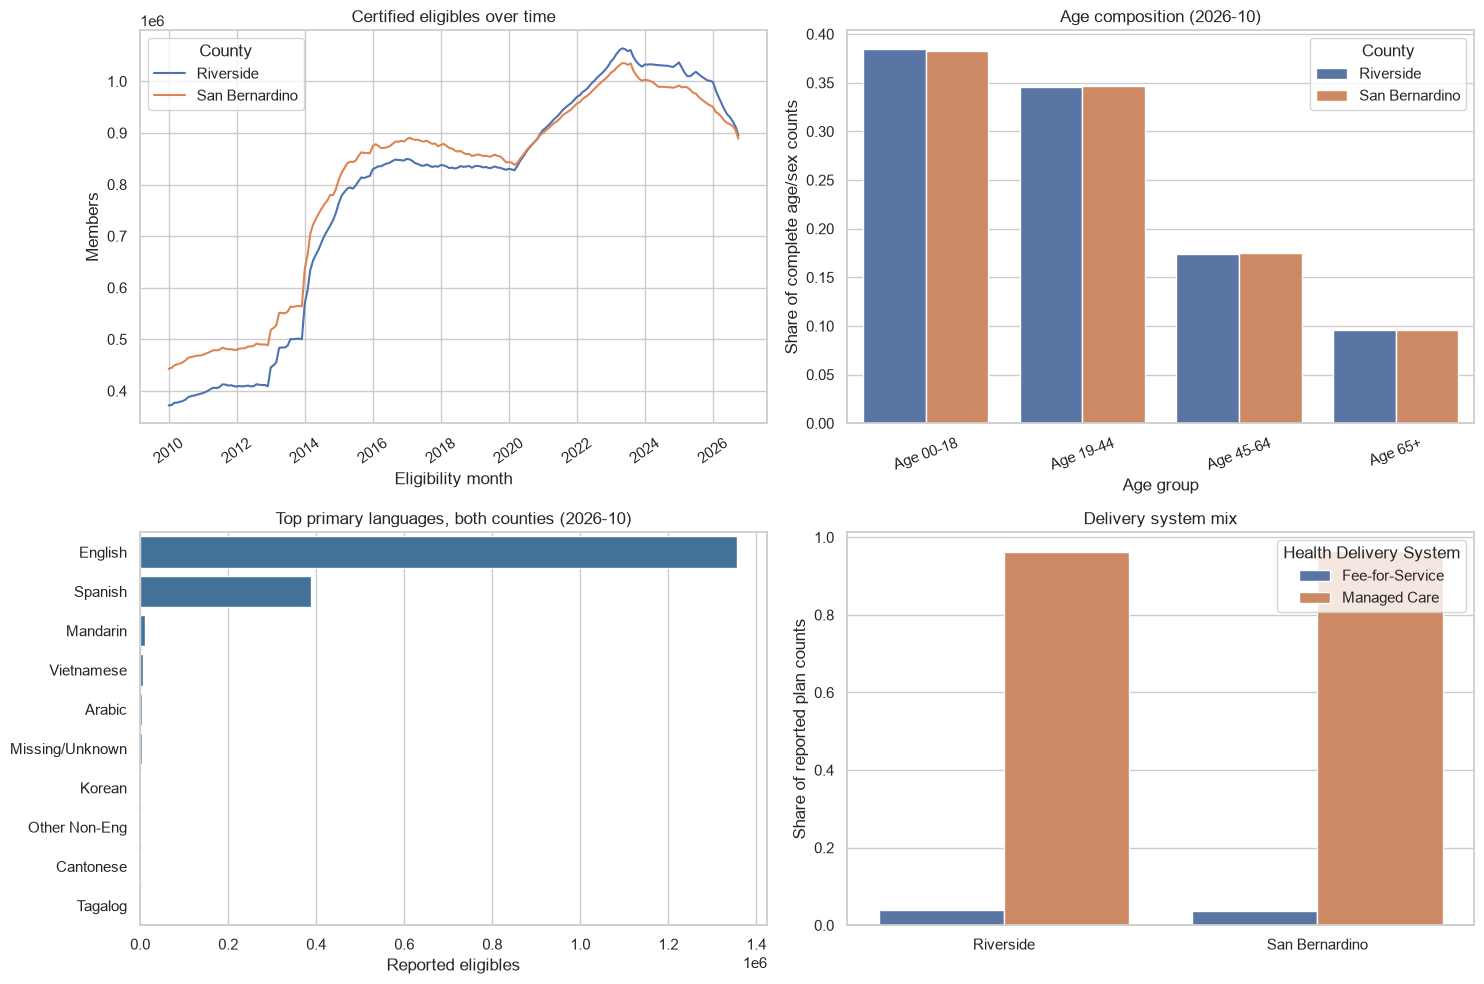

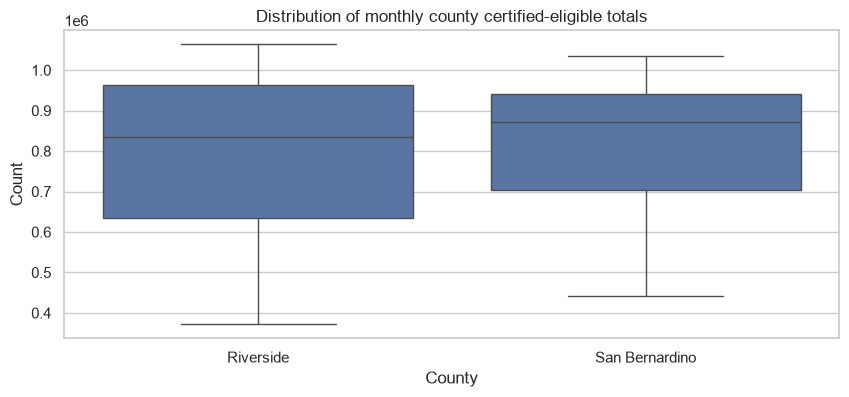

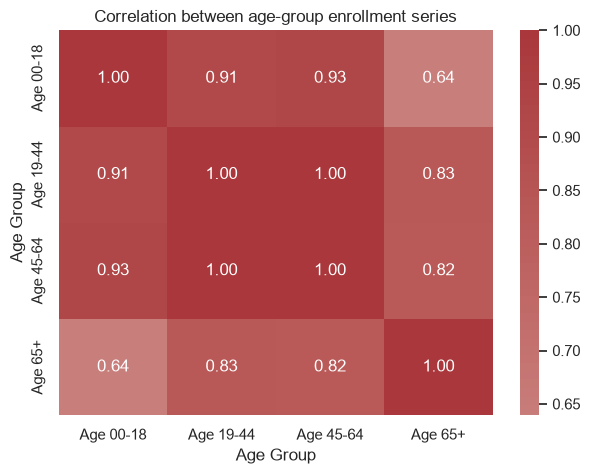

In [17]:
ie = {name: frame.loc[frame["County"].isin(COUNTIES)].copy() for name, frame in tables.items()}

# Overall monthly county totals are rebuilt from the eight age-by-gender cells.
monthly_county_totals = complete_group_sum(
    ie["age_sex"], ["Eligibility_Month", "County"]
).sort_values(["County", "Eligibility_Month"])
latest_totals = monthly_county_totals.loc[
    monthly_county_totals["Eligibility_Month"].eq(pd.Timestamp(selected_month + "-01"))
].copy()
print(f"Latest reported county totals ({selected_month}; complete groups only):")
display(latest_totals[["County", "Count", "complete"]])

age_latest = complete_group_sum(
    ie["age_sex"].loc[ie["age_sex"]["Month of Eligibility"].eq(selected_month)],
    ["County", "Age Group"],
)
age_latest["Share"] = age_latest["Count"] / age_latest.groupby("County")["Count"].transform("sum")
lang_latest = complete_group_sum(
    ie["primary_language"].loc[ie["primary_language"]["Month of Eligibility"].eq(selected_month)],
    ["County", "Language"],
)
lang_latest["Share_of_reported"] = lang_latest["Count"] / lang_latest.groupby("County")["Count"].transform("sum")
race_latest = complete_group_sum(
    ie["race_age"].loc[ie["race_age"]["Month of Eligibility"].eq(selected_month)],
    ["County", "Age Group", "Ethnicity"],
)
race_latest["Share_within_county_age"] = race_latest["Count"] / race_latest.groupby(
    ["County", "Age Group"]
)["Count"].transform("sum")
dual_age_latest = complete_group_sum(
    ie["dual_age"].loc[ie["dual_age"]["Month of Eligibility"].eq(selected_month)],
    ["County", "Dual Status", "Age Group"],
)
plan_latest = complete_group_sum(
    ie["delivery_plan"].loc[ie["delivery_plan"]["Month of Eligibility"].eq(selected_month)],
    ["County", "Health Delivery System", "Health Plan"],
)

print("\nAge mix:")
display(age_latest.sort_values(["County", "Age Group"]))
print("\nTop primary languages by county (reported counts):")
display(lang_latest.sort_values(["County", "Count"], ascending=[True, False]).groupby("County").head(10))
print("\nRace/ethnicity by age group:")
display(race_latest.sort_values(["County", "Age Group", "Count"], ascending=[True, True, False]))
print("\nDual status by age:")
display(dual_age_latest.sort_values(["County", "Age Group", "Dual Status"]))

# Cross-table reconciliation is diagnostic: suppressed cells or differing table definitions can produce gaps.
reconciliation = []
for county in COUNTIES:
    age_total = latest_totals.loc[latest_totals["County"].eq(county), "Count"]
    for table_name, summary in [
        ("primary_language", lang_latest),
        ("race_age", race_latest),
        ("dual_age", dual_age_latest),
    ]:
        county_total = summary.loc[summary["County"].eq(county), "Count"].sum(min_count=1)
        reconciliation.append({
            "County": county,
            "comparison": table_name,
            "age_sex_total": age_total.iloc[0] if not age_total.empty else np.nan,
            "demographic_table_reported_sum": county_total,
            "difference": county_total - age_total.iloc[0] if not age_total.empty and pd.notna(county_total) else np.nan,
        })
display(pd.DataFrame(reconciliation))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.lineplot(data=monthly_county_totals.dropna(subset=["Count"]), x="Eligibility_Month", y="Count", hue="County", ax=axes[0, 0])
axes[0, 0].set(title="Certified eligibles over time", xlabel="Eligibility month", ylabel="Members")
axes[0, 0].tick_params(axis="x", rotation=35)
sns.barplot(data=age_latest, x="Age Group", y="Share", hue="County", ax=axes[0, 1])
axes[0, 1].set(title=f"Age composition ({selected_month})", ylabel="Share of complete age/sex counts", xlabel="Age group")
axes[0, 1].tick_params(axis="x", rotation=20)
combined_lang = lang_latest.groupby("Language", as_index=False)["Count"].sum(min_count=1).nlargest(10, "Count")
sns.barplot(data=combined_lang, x="Count", y="Language", color="#3572A5", ax=axes[1, 0])
axes[1, 0].set(title=f"Top primary languages, both counties ({selected_month})", xlabel="Reported eligibles", ylabel="")
plan_mix = plan_latest.groupby(["County", "Health Delivery System"], as_index=False)["Count"].sum(min_count=1)
plan_mix["Share"] = plan_mix["Count"] / plan_mix.groupby("County")["Count"].transform("sum")
sns.barplot(data=plan_mix, x="County", y="Share", hue="Health Delivery System", ax=axes[1, 1])
axes[1, 1].set(title="Delivery system mix", ylabel="Share of reported plan counts", xlabel="")
plt.tight_layout()
plt.show()

# Numeric distribution screens and age-group correlation across monthly IE county observations.
plt.figure(figsize=(10, 4))
sns.boxplot(data=monthly_county_totals.dropna(subset=["Count"]), x="County", y="Count")
plt.title("Distribution of monthly county certified-eligible totals")
plt.show()

# Combine both counties before pivoting so month/age is a unique pair.
age_monthly = complete_group_sum(ie["age_sex"], ["Eligibility_Month", "Age Group"])
age_pivot = age_monthly.pivot(index="Eligibility_Month", columns="Age Group", values="Count")
plt.figure(figsize=(7, 5))
sns.heatmap(age_pivot.corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation between age-group enrollment series")
plt.show()

## 6. Segment and Cohort Analysis

Compare latest age composition with the nearest available prior reporting month to the 12-month mark, and follow the reported FFS/managed-care mix over time. If the exact year-ago month is absent, the notebook uses and labels the nearest available earlier month. These cohort views help locate population shifts and transition exposure, but plan assignment and demographic tables are separate aggregates; they cannot be joined to identify the characteristics of IEHP members who may transition.

Age cohort comparison: 2025-11 vs 2026-10 (11 months apart)


/var/folders/r1/wcgb5bvd0psc8_72j7gz97lr0000gp/T/ipykernel_40840/2950197383.py:30: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  age_cohort_pivot["change_pct_vs_comparison"] = (
/var/folders/r1/wcgb5bvd0psc8_72j7gz97lr0000gp/T/ipykernel_40840/2950197383.py:33: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  age_cohort_pivot["share_change_pp_vs_comparison"] = (


County  Age Group   Count           Share         change_pct_vs_comparison share_change_pp_vs_comparison
Month                            2025-11 2026-10 2025-11 2026-10                                                       
0           Riverside  Age 00-18  374731  344160    0.37    0.38                    -8.16                          1.05
1           Riverside  Age 19-44  357772  309577    0.36    0.35                   -13.47                         -1.12
2           Riverside  Age 45-64  176387  155715    0.18    0.17                   -11.72                         -0.21
3           Riverside    Age 65+   92920   85583    0.09    0.10                    -7.90                          0.29
4      San Bernardino  Age 00-18  360239  340142    0.38    0.38                    -5.58                          0.61
5      San Bernardino  Age 19-44  339983  308306    0.36    0.35                    -9.32                         -0.86
6      San Bernardino  Age 45-64  167956  155417    0.18    0.17                    -7.47                         -0.07
7      San Bernardino    Age 65+   88336   84974    0.09    0.10                    -3.81                          0.32

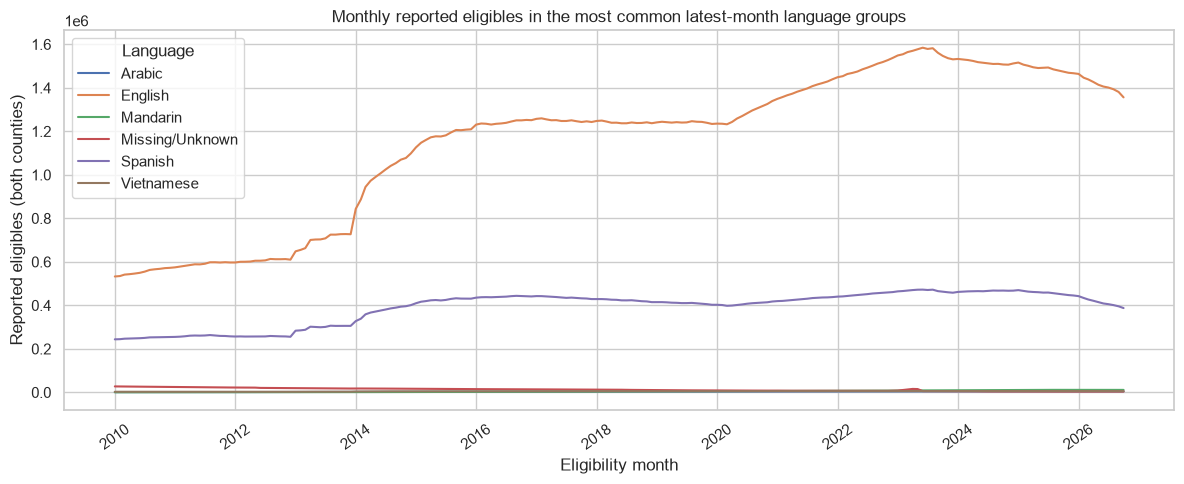

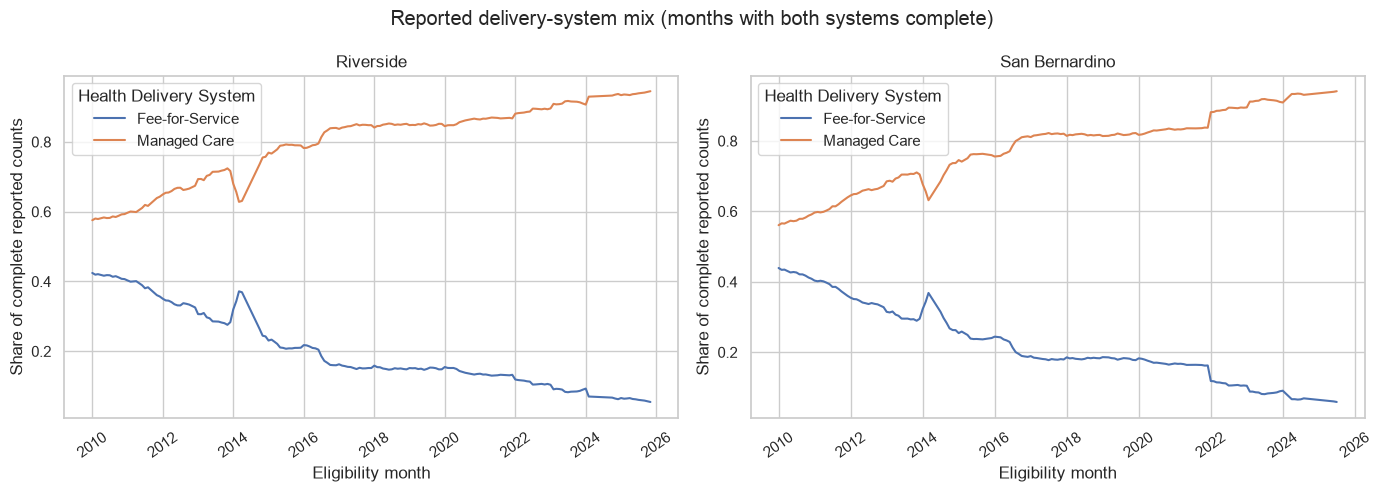


IEHP-labeled latest-month plan rows in Source B:


,County,Health Delivery System,Health Plan,Count,valid_cells,source_cells,complete
1,Riverside,Managed Care,Inland Empire Health Plan/Riverside,667613,1,1,True
14,San Bernardino,Managed Care,Inland Empire Health Plan/San Bernardino,669927,1,1,True


In [18]:
age_by_month = complete_group_sum(
    ie["age_sex"], ["Eligibility_Month", "County", "Age Group"]
)
age_by_month = age_by_month.loc[age_by_month["complete"]].copy()
age_by_month["Share"] = age_by_month["Count"] / age_by_month.groupby(
    ["Eligibility_Month", "County"]
)["Count"].transform("sum")
available_months = sorted(age_by_month["Eligibility_Month"].dt.to_period("M").unique())
target_comparison_period = selected_month_dt - 12
prior_months = [period for period in available_months if period < selected_month_dt]
if not prior_months:
    raise ValueError("No earlier complete month is available for cohort comparison.")
compare_period = min(
    prior_months,
    key=lambda period: (abs(period.ordinal - target_comparison_period.ordinal), -period.ordinal),
)
compare_month = compare_period.strftime("%Y-%m")
age_cohort = age_by_month.loc[
    age_by_month["Eligibility_Month"].dt.to_period("M").isin([compare_period, selected_month_dt])
].copy()
age_cohort["Month"] = age_cohort["Eligibility_Month"].dt.strftime("%Y-%m")
age_cohort_pivot = age_cohort.pivot_table(
    index=["County", "Age Group"], columns="Month", values=["Count", "Share"], aggfunc="first"
)
count_before = ("Count", compare_month)
count_latest = ("Count", selected_month)
share_before = ("Share", compare_month)
share_latest = ("Share", selected_month)
if count_before in age_cohort_pivot and count_latest in age_cohort_pivot:
    age_cohort_pivot["change_pct_vs_comparison"] = (
        age_cohort_pivot[count_latest] / age_cohort_pivot[count_before] - 1
    ) * 100
    age_cohort_pivot["share_change_pp_vs_comparison"] = (
        age_cohort_pivot[share_latest] - age_cohort_pivot[share_before]
    ) * 100
print(
    f"Age cohort comparison: {compare_month} vs {selected_month} "
    f"({selected_month_dt.ordinal - compare_period.ordinal} months apart)"
)
display(age_cohort_pivot.reset_index())

# Top reported languages at the latest month, followed as a fixed cohort through time.
top_languages = (
    lang_latest.groupby("Language")["Count"].sum(min_count=1).nlargest(6).index.tolist()
)
language_trend = complete_group_sum(
    ie["primary_language"].loc[ie["primary_language"]["Language"].isin(top_languages)],
    ["Eligibility_Month", "Language"],
)
language_trend = language_trend.loc[language_trend["complete"]]
plt.figure(figsize=(12, 5))
sns.lineplot(data=language_trend, x="Eligibility_Month", y="Count", hue="Language")
plt.title("Monthly reported eligibles in the most common latest-month language groups")
plt.xlabel("Eligibility month")
plt.ylabel("Reported eligibles (both counties)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

system_trend = complete_group_sum(
    ie["delivery_plan"], ["Eligibility_Month", "County", "Health Delivery System"]
)
system_coverage = system_trend.groupby(
    ["Eligibility_Month", "County"]
).agg(
    system_categories=("Health Delivery System", "nunique"),
    complete_system_categories=("complete", "sum"),
).reset_index()
system_coverage["all_systems_complete"] = system_coverage["system_categories"].eq(
    system_coverage["complete_system_categories"]
)
system_trend = system_trend.merge(
    system_coverage.loc[system_coverage["all_systems_complete"], ["Eligibility_Month", "County"]],
    on=["Eligibility_Month", "County"],
    how="inner",
)
system_trend["Share"] = system_trend["Count"] / system_trend.groupby(
    ["Eligibility_Month", "County"]
)["Count"].transform("sum")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, county in zip(axes, COUNTIES):
    subset = system_trend.loc[system_trend["County"].eq(county)]
    sns.lineplot(data=subset, x="Eligibility_Month", y="Share", hue="Health Delivery System", ax=ax)
    ax.set(title=county, xlabel="Eligibility month", ylabel="Share of complete reported counts")
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("Reported delivery-system mix (months with both systems complete)")
plt.tight_layout()
plt.show()

# Plan-level latest-month view; highlight IEHP only when the name appears in the source.
iehp_latest_plan = plan_latest.loc[
    plan_latest["Health Plan"].str.contains("inland empire health plan|iehp", case=False, na=False)
].copy()
print("\nIEHP-labeled latest-month plan rows in Source B:")
display(iehp_latest_plan if not iehp_latest_plan.empty else pd.DataFrame({"note": ["No IEHP-labeled plan row found in the selected month."]}))

## 7. Statistical Testing of Key Hypotheses

**Hypothesis:** For each demographic dimension, the distribution of reported certified eligibles differs between Riverside and San Bernardino counties in the latest common month. Use chi-square tests of independence and Cramér’s V; combine rare categories if expected cell counts are below five and adjust p-values across dimensions (Benjamini–Hochberg). Wilson intervals describe selected language shares. These are descriptive population-count comparisons—not causal or individual-level tests—and monthly records are not treated as independent observations.

In [19]:
latest_rows = {name: frame.loc[frame["Month of Eligibility"].eq(selected_month)] for name, frame in ie.items()}
distributions = {
    "Age group": complete_group_sum(latest_rows["age_sex"], ["County", "Age Group"]).rename(columns={"Age Group": "Category"}),
    "Primary language": complete_group_sum(latest_rows["primary_language"], ["County", "Language"]).rename(columns={"Language": "Category"}),
    "Race/ethnicity": complete_group_sum(latest_rows["race_age"], ["County", "Ethnicity"]).rename(columns={"Ethnicity": "Category"}),
    "Medicare dual status": complete_group_sum(latest_rows["dual_status"], ["County", "Dual Status"]).rename(columns={"Dual Status": "Category"}),
}

def chi_square_distribution(label: str, summary: pd.DataFrame) -> dict:
    usable = summary.loc[summary["complete"], ["County", "Category", "Count"]]
    matrix = usable.pivot(index="County", columns="Category", values="Count").reindex(COUNTIES)
    matrix = matrix.dropna(axis=1, how="any").fillna(0)
    matrix = matrix.loc[:, matrix.sum(axis=0).gt(0)].astype(float)
    if matrix.shape[1] < 2 or matrix.shape[0] != 2:
        return {"dimension": label, "categories_tested": matrix.shape[1], "chi2": np.nan, "p_value": np.nan, "cramers_v": np.nan, "small_expected_categories_merged": np.nan}
    merged_count = 0
    while matrix.shape[1] > 2:
        _, _, _, expected = chi2_contingency(matrix.to_numpy(dtype=float), correction=False)
        sparse = np.any(expected < 5, axis=0)
        if not sparse.any():
            break
        rare_names = matrix.columns[sparse]
        rare_total = matrix.loc[:, rare_names].sum(axis=1)
        matrix = matrix.loc[:, ~sparse].copy()
        matrix["Other (low frequency)"] = rare_total
        merged_count += len(rare_names)
    chi2, p_value, _, expected = chi2_contingency(matrix.to_numpy(dtype=float), correction=False)
    total = matrix.to_numpy(dtype=float).sum()
    cramers_v = np.sqrt(chi2 / (total * min(matrix.shape[0] - 1, matrix.shape[1] - 1)))
    return {
        "dimension": label,
        "categories_tested": matrix.shape[1],
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v,
        "small_expected_categories_merged": merged_count,
        "min_expected_count": expected.min(),
        "known_count_total": total,
    }

test_results = pd.DataFrame(
    [chi_square_distribution(label, summary) for label, summary in distributions.items()]
)
valid_p = test_results["p_value"].notna()
test_results["p_value_BH_adjusted"] = np.nan
if valid_p.any():
    test_results.loc[valid_p, "p_value_BH_adjusted"] = multipletests(
        test_results.loc[valid_p, "p_value"], method="fdr_bh"
    )[1]
print(f"County demographic distribution tests ({selected_month}):")
display(test_results)

# 95% Wilson confidence intervals for the top six reported language groups in each county.
top_lang_names = lang_latest.groupby("Language")["Count"].sum(min_count=1).nlargest(6).index
language_ci_rows = []
for county in COUNTIES:
    county_language = lang_latest.loc[
        lang_latest["County"].eq(county) & lang_latest["Language"].isin(top_lang_names) & lang_latest["complete"]
    ]
    denominator = lang_latest.loc[
        lang_latest["County"].eq(county) & lang_latest["complete"], "Count"
    ].sum()
    for row in county_language.itertuples(index=False):
        count = int(row.Count)
        lower, upper = proportion_confint(count, int(denominator), alpha=0.05, method="wilson")
        language_ci_rows.append({
            "County": county,
            "Language": row.Language,
            "reported_count": count,
            "share_pct": count / denominator * 100,
            "95pct_CI_lower_pct": lower * 100,
            "95pct_CI_upper_pct": upper * 100,
        })
language_ci = pd.DataFrame(language_ci_rows)
print("\nWilson 95% intervals for selected language shares (denominator = numeric reported language counts):")
display(language_ci)

County demographic distribution tests (2026-10):


,dimension,categories_tested,chi2,p_value,cramers_v,small_expected_categories_merged,min_expected_count,known_count_total,p_value_BH_adjusted
0,Age group,4,7.15,0.07,0.00,0,"84,982.30","1,783,874.00",0.07
1,Primary language,27,"5,791.60",0.00,0.06,0,27.90,"1,783,782.00",0.00
2,Race/ethnicity,6,"12,902.45",0.00,0.09,0,"1,974.12","1,783,874.00",0.00
3,Medicare dual status,2,13.77,0.00,0.00,0,"98,106.55","1,783,874.00",0.00



Wilson 95% intervals for selected language shares (denominator = numeric reported language counts):


,County,Language,reported_count,share_pct,95pct_CI_lower_pct,95pct_CI_upper_pct
0,Riverside,Arabic,2194,0.25,0.24,0.26
1,Riverside,English,669068,74.75,74.66,74.84
2,Riverside,Mandarin,3134,0.35,0.34,0.36
3,Riverside,Missing/Unknown,2068,0.23,0.22,0.24
4,Riverside,Spanish,208816,23.33,23.24,23.42
5,Riverside,Vietnamese,2648,0.30,0.28,0.31
6,San Bernardino,Arabic,2317,0.26,0.25,0.27
7,San Bernardino,English,687027,77.30,77.21,77.38
8,San Bernardino,Mandarin,8222,0.93,0.91,0.95
9,San Bernardino,Missing/Unknown,1679,0.19,0.18,0.20


## 8. Build a Baseline Predictive Model

Target: monthly combined certified eligibles in Riverside and San Bernardino. Fit a Ridge regression with calendar seasonality and one-/12-month lags, using a chronological 12-month holdout. Compare it with a seasonal-naive forecast (same month last year). This is an enrollment-trend benchmark only—not an estimate of IEHP UIS membership, policy-driven departures, or healthcare need.

Chronological holdout: 2025-08 through 2026-09


,model,test_months,MAE,RMSE,MAPE_pct
0,Ridge seasonal + lags,12,"25,351.30","26,581.13",1.34
1,Seasonal naive (lag 12),12,"103,213.67","110,327.55",5.49


Ridge standardized coefficients (associations, not causal effects):


,feature,standardized_coefficient
3,lag_1,"374,801.73"
0,trend,"9,264.91"
1,month_sin,"2,275.90"
4,lag_12,"-1,518.85"
2,month_cos,985.36


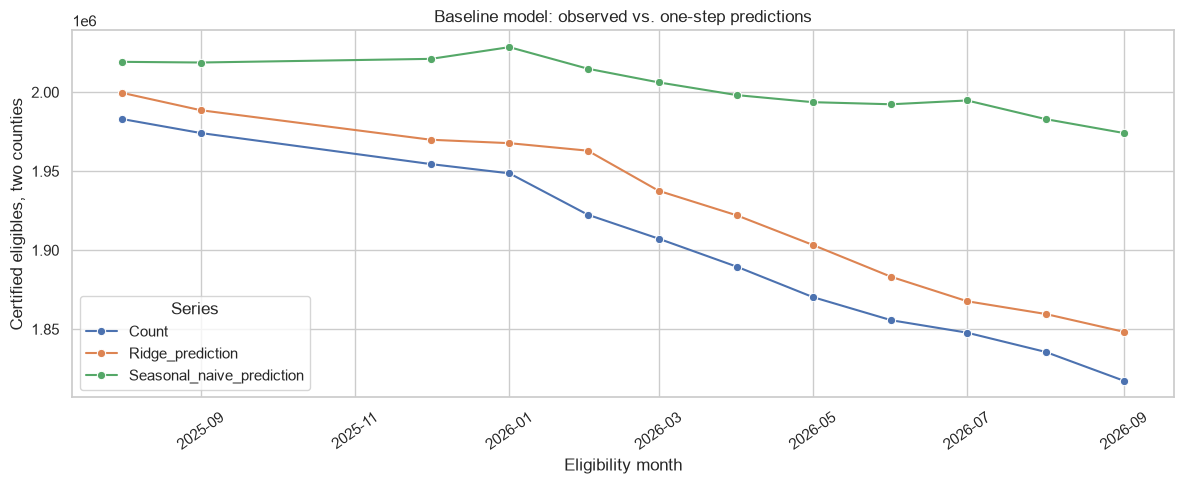

In [20]:
model_series = complete_group_sum(ie["age_sex"], ["Eligibility_Month"])
model_series = model_series[["Eligibility_Month", "Count"]].sort_values("Eligibility_Month")
if model_series.empty:
    raise ValueError("No monthly Inland Empire totals are available for the baseline model.")

# Reindex to a complete monthly calendar so lag_12 always means exactly 12 months earlier.
monthly_index = pd.date_range(
    model_series["Eligibility_Month"].min(),
    model_series["Eligibility_Month"].max(),
    freq="MS",
)
model_series = (
    model_series.set_index("Eligibility_Month")
    .reindex(monthly_index)
    .rename_axis("Eligibility_Month")
    .reset_index()
)
model_series["month_index"] = model_series["Eligibility_Month"].dt.year * 12 + model_series["Eligibility_Month"].dt.month
model_series["trend"] = model_series["month_index"] - model_series["month_index"].min()
model_series["month_sin"] = np.sin(2 * np.pi * model_series["Eligibility_Month"].dt.month / 12)
model_series["month_cos"] = np.cos(2 * np.pi * model_series["Eligibility_Month"].dt.month / 12)
model_series["lag_1"] = model_series["Count"].shift(1)
model_series["lag_12"] = model_series["Count"].shift(12)
feature_columns = ["trend", "month_sin", "month_cos", "lag_1", "lag_12"]
model_data = model_series.dropna(subset=["Count", *feature_columns]).copy()
if len(model_data) <= 12:
    raise ValueError("At least 13 usable monthly observations are needed for a 12-month test set.")

test_size = 12
test_start = len(model_data) - test_size
train = model_data.iloc[:test_start]
test = model_data.iloc[test_start:].copy()
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
model.fit(train[feature_columns], train["Count"])
test["Ridge_prediction"] = model.predict(test[feature_columns])
test["Seasonal_naive_prediction"] = test["lag_12"]

model_metrics = pd.DataFrame([
    {
        "model": model_name,
        "test_months": len(test),
        "MAE": mean_absolute_error(test["Count"], test[prediction_column]),
        "RMSE": np.sqrt(mean_squared_error(test["Count"], test[prediction_column])),
        "MAPE_pct": np.mean(np.abs((test["Count"] - test[prediction_column]) / test["Count"])) * 100,
    }
    for model_name, prediction_column in [
        ("Ridge seasonal + lags", "Ridge_prediction"),
        ("Seasonal naive (lag 12)", "Seasonal_naive_prediction"),
    ]
])
print(f"Chronological holdout: {test['Eligibility_Month'].min():%Y-%m} through {test['Eligibility_Month'].max():%Y-%m}")
display(model_metrics)

ridge_model = model.named_steps["ridge"]
coefficient_table = pd.DataFrame({
    "feature": feature_columns,
    "standardized_coefficient": ridge_model.coef_,
}).sort_values("standardized_coefficient", key=lambda values: values.abs(), ascending=False)
print("Ridge standardized coefficients (associations, not causal effects):")
display(coefficient_table)

test_plot = test.melt(
    id_vars="Eligibility_Month",
    value_vars=["Count", "Ridge_prediction", "Seasonal_naive_prediction"],
    var_name="Series",
    value_name="Eligibles",
)
plt.figure(figsize=(12, 5))
sns.lineplot(data=test_plot, x="Eligibility_Month", y="Eligibles", hue="Series", marker="o")
plt.title("Baseline model: observed vs. one-step predictions")
plt.xlabel("Eligibility month")
plt.ylabel("Certified eligibles, two counties")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 9. Generate Insights Table and Export Results

Build a concise, reproducible scorecard, save the cleaned Source B tables and analytical summaries, and export a figure for downstream reporting. Outputs go to `analysis_outputs/source_b/` within the repository.

Executive scorecard (descriptive; not UIS-specific):


,metric,value,interpretation
0,"Combined certified eligibles, Riverside + San ...",1783874,Latest common month 2026-10; county totals req...
1,Certified eligibles — Riverside,895035,2026-10; all age-by-gender cells complete=True.
2,Certified eligibles — San Bernardino,888839,2026-10; all age-by-gender cells complete=True.
3,Largest age group — Riverside,Age 00-18,38.5% of complete age/sex count.
4,Most reported primary language — Riverside,English,74.8% of numeric reported language counts; not...
5,Largest age group — San Bernardino,Age 00-18,38.3% of complete age/sex count.
6,Most reported primary language — San Bernardino,English,77.3% of numeric reported language counts; not...
7,Fee-for-Service share — Riverside,0.04,Share of numeric reported Source B delivery-sy...
8,Managed Care share — Riverside,0.96,Share of numeric reported Source B delivery-sy...
9,Fee-for-Service share — San Bernardino,0.04,Share of numeric reported Source B delivery-sy...


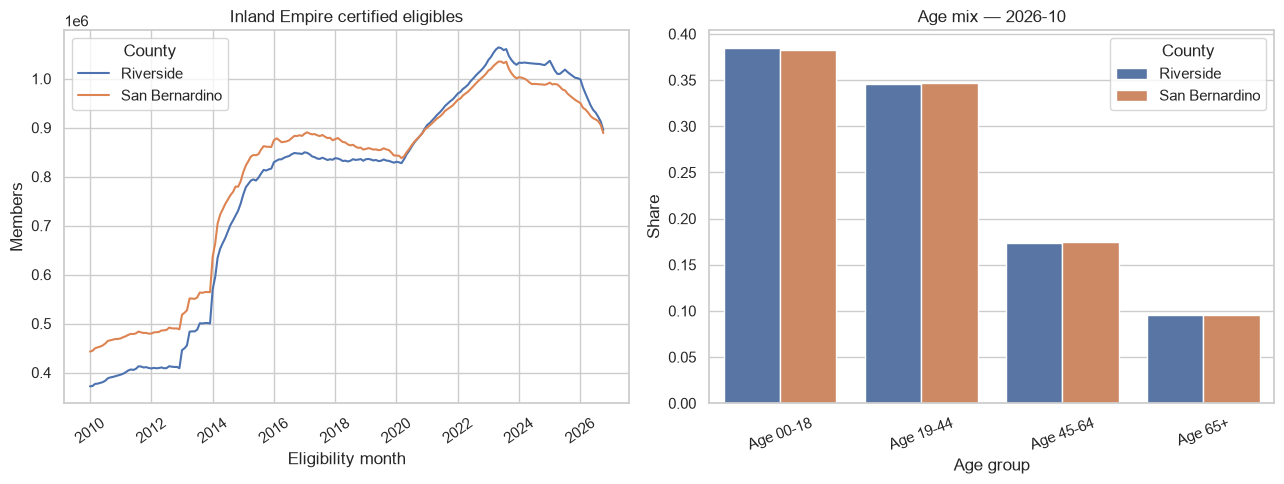


Exported cleaned tables, summaries, model outputs, scorecard, and figure to: /Users/Jonny/ceo-challenge/IEHP-CEO-Competition/analysis_outputs/source_b
Key files: source_b_trends_and_age_mix.png executive_scorecard.csv county_distribution_tests.csv baseline_model_metrics.csv


In [22]:
insight_rows = []
combined_total = latest_totals["Count"].sum(min_count=2)
if pd.notna(combined_total):
    insight_rows.append({"metric": "Combined certified eligibles, Riverside + San Bernardino", "value": combined_total, "interpretation": f"Latest common month {selected_month}; county totals require all age-by-gender cells."})
for row in latest_totals.itertuples(index=False):
    insight_rows.append({"metric": f"Certified eligibles — {row.County}", "value": row.Count, "interpretation": f"{selected_month}; all age-by-gender cells complete={row.complete}."})
for county in COUNTIES:
    county_age = age_latest.loc[age_latest["County"].eq(county) & age_latest["complete"]]
    if not county_age.empty:
        lead = county_age.sort_values("Count", ascending=False).iloc[0]
        insight_rows.append({"metric": f"Largest age group — {county}", "value": lead["Age Group"], "interpretation": f"{lead['Share']:.1%} of complete age/sex count."})
    county_lang = lang_latest.loc[lang_latest["County"].eq(county) & lang_latest["complete"]]
    if not county_lang.empty:
        lead = county_lang.sort_values("Count", ascending=False).iloc[0]
        denominator = county_lang["Count"].sum()
        insight_rows.append({"metric": f"Most reported primary language — {county}", "value": lead["Language"], "interpretation": f"{lead['Count'] / denominator:.1%} of numeric reported language counts; not an English-proficiency measure."})
plan_system_rows = plan_mix.loc[
    plan_mix["Health Delivery System"].str.contains("fee-for-service|managed care", case=False, na=False)
]
for county_name, system_name, system_count, system_share in plan_system_rows.itertuples(index=False, name=None):
    insight_rows.append({"metric": f"{system_name} share — {county_name}", "value": system_share, "interpretation": f"Share of numeric reported Source B delivery-system counts in {selected_month}."})
if not iehp_latest_plan.empty:
    insight_rows.append({"metric": "IEHP-labeled Source B plan count", "value": iehp_latest_plan["Count"].sum(min_count=1), "interpretation": f"Latest county-level plan-table count; not IEHP's verified UIS or total member count."})
if not test_results.empty:
    strongest = test_results.dropna(subset=["cramers_v"]).sort_values("cramers_v", ascending=False).head(1)
    if not strongest.empty:
        test_row = strongest.iloc[0]
        insight_rows.append({"metric": "Largest county distribution effect size", "value": test_row["dimension"], "interpretation": f"Cramér's V={test_row['cramers_v']:.3f}; BH-adjusted p={test_row['p_value_BH_adjusted']:.3g}."})
if not model_metrics.empty:
    best_model = model_metrics.sort_values("MAE").iloc[0]
    insight_rows.append({"metric": "Best 12-month holdout model by MAE", "value": best_model["model"], "interpretation": f"MAE={best_model['MAE']:,.0f} members; historical enrollment trend only."})

insights_table = pd.DataFrame(insight_rows)
print("Executive scorecard (descriptive; not UIS-specific):")
display(insights_table)

# Save derived, cleaned source tables and reusable analysis results.
for table_name, frame in tables.items():
    frame.to_csv(output_dir / f"cleaned_{table_name}.csv", index=False)
profile_df.to_csv(output_dir / "schema_quality_profile.csv", index=False)
cleaning_log_df.to_csv(output_dir / "cleaning_log.csv", index=False)
latest_totals.to_csv(output_dir / "latest_county_totals.csv", index=False)
age_latest.to_csv(output_dir / "latest_age_summary.csv", index=False)
lang_latest.to_csv(output_dir / "latest_language_summary.csv", index=False)
race_latest.to_csv(output_dir / "latest_race_ethnicity_age_summary.csv", index=False)
dual_age_latest.to_csv(output_dir / "latest_dual_status_age_summary.csv", index=False)
plan_latest.to_csv(output_dir / "latest_delivery_plan_summary.csv", index=False)
test_results.to_csv(output_dir / "county_distribution_tests.csv", index=False)
language_ci.to_csv(output_dir / "language_share_wilson_intervals.csv", index=False)
model_metrics.to_csv(output_dir / "baseline_model_metrics.csv", index=False)
test.to_csv(output_dir / "baseline_model_test_predictions.csv", index=False)
coefficient_table.to_csv(output_dir / "baseline_model_coefficients.csv", index=False)
insights_table.to_csv(output_dir / "executive_scorecard.csv", index=False)

# Export a compact report-ready visualization.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.lineplot(data=monthly_county_totals.dropna(subset=["Count"]), x="Eligibility_Month", y="Count", hue="County", ax=axes[0])
axes[0].set(title="Inland Empire certified eligibles", xlabel="Eligibility month", ylabel="Members")
axes[0].tick_params(axis="x", rotation=35)
sns.barplot(data=age_latest, x="Age Group", y="Share", hue="County", ax=axes[1])
axes[1].set(title=f"Age mix — {selected_month}", xlabel="Age group", ylabel="Share")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
figure_path = output_dir / "source_b_trends_and_age_mix.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"\nExported cleaned tables, summaries, model outputs, scorecard, and figure to: {output_dir}")
print("Key files:", figure_path.name, "executive_scorecard.csv", "county_distribution_tests.csv", "baseline_model_metrics.csv")